### Import Data

In [71]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost.sklearn import XGBClassifier
import xgboost as xgb

print(os.getcwd())
df = pd.read_csv("../dataset/fab.csv")

d:\CODE\MyNote\SemiconductorData\code


### Data Information

In [2]:
df.info()

# dtypes: float64(590) -> Sensor, int64(1) -> Pass_Fail, str(1) -> SensorTime
df.dtypes 

df.describe()

df.head()
df.tail()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 592 entries, SensorTime to Pass_Fail
dtypes: float64(590), int64(1), str(1)
memory usage: 7.1 MB


,SensorTime,Sensor0,Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,...,Sensor581,Sensor582,Sensor583,Sensor584,Sensor585,Sensor586,Sensor587,Sensor588,Sensor589,Pass_Fail
1562,2008-10-16 15:13:00,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,...,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720,-1
1563,2008-10-16 20:49:00,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,...,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720,-1
1564,2008-10-17 05:26:00,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,...,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231,-1
1565,2008-10-17 06:01:00,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,...,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941,-1
1566,2008-10-17 06:07:00,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,...,137.7844,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844,-1


### Set Target / Feature

In [3]:
target_col = "Pass_Fail"

feature_cols = [
    col for col in df.columns 
    if col not in ['Pass_Fail', 'SensorTime']
]

X = df[feature_cols]
y = df[target_col]

### Split Target / Test

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
) 

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(1175, 590)
(392, 590)
(1175,)
(392,)


### Data Visualization

- 정상/불량 비율 확인

Pass_Fail
-1    1097
 1      78
Name: count, dtype: int64


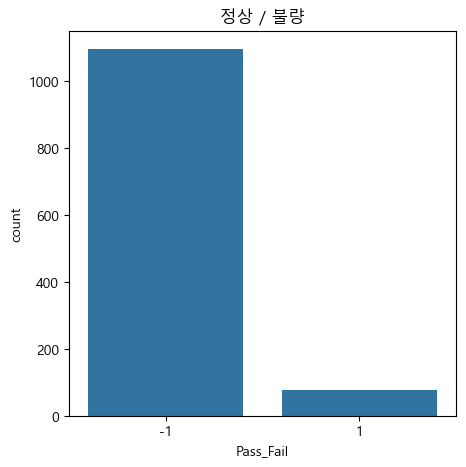

In [5]:
train_df = X_train.copy()
train_df[target_col] = y_train

print(y_train.value_counts())

plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

plt.figure(figsize=(5,5))
sns.countplot(x=target_col, data=train_df)
plt.title('정상 / 불량')
plt.show()

- 센서별 Pass / Fail 데이터 분포

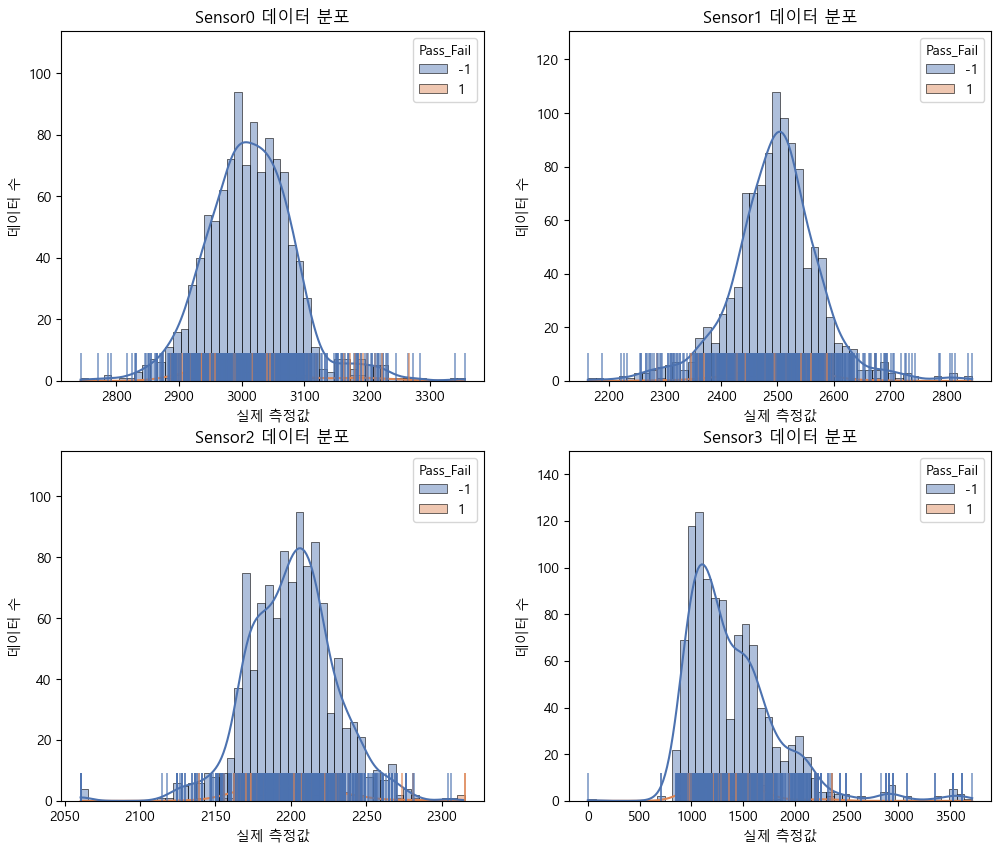

In [6]:
palette = {
    -1: "#4C72B0",   # Pass
     1: "#DD8452"    # Fail
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, sensor in enumerate(feature_cols[0:4]):
    sns.histplot(data=train_df,
                x=sensor,
                hue=target_col,
                bins=50,
                kde=True,
                palette=palette,
                alpha=0.45,
                edgecolor="black",
                linewidth=0.4,
                multiple="layer",
                ax=axes[i])
    sns.rugplot(data=train_df,
                x=sensor,
                hue=target_col,
                palette=palette,
                height=0.08,
                alpha=0.7,
                linewidth=1.2,
                ax=axes[i],
                legend=False)

    axes[i].set_title(f"{sensor} 데이터 분포")
    axes[i].set_xlabel("실제 측정값")
    axes[i].set_ylabel("데이터 수")

### Data Preprocessing

- 결측치 처리 

In [7]:
# 결측값이 높은 feature 제거
missing_ratio = X_train.isnull().mean().sort_values(ascending=False) * 100
high_missing_features = missing_ratio[missing_ratio > 70 ].index.tolist()

X_train = X_train.drop(columns=high_missing_features)
X_test = X_test.drop(columns=high_missing_features)

# 나머지 결측치 데이터 중앙값으로 처리
median_values = X_train.median()

X_train = X_train.fillna(median_values)
X_test = X_test.fillna(median_values)

print(X_train.isna().sum().sum())
print(X_test.isna().sum().sum())

0
0


- 중복 데이터 처리

In [8]:
duplicate_count = df.duplicated(subset=feature_cols + [target_col]).sum()
duplicate_count
# 중복 데이터 확인 결과, 전체 행 기준 중복 데이터는 존재하지 않았다.

np.int64(0)

- 이상치 처리

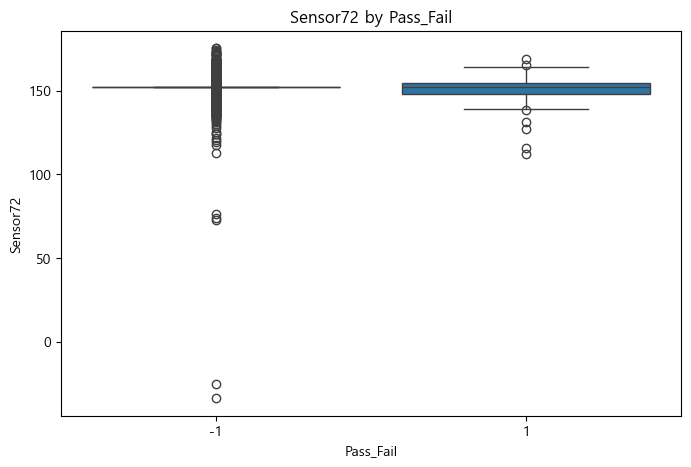

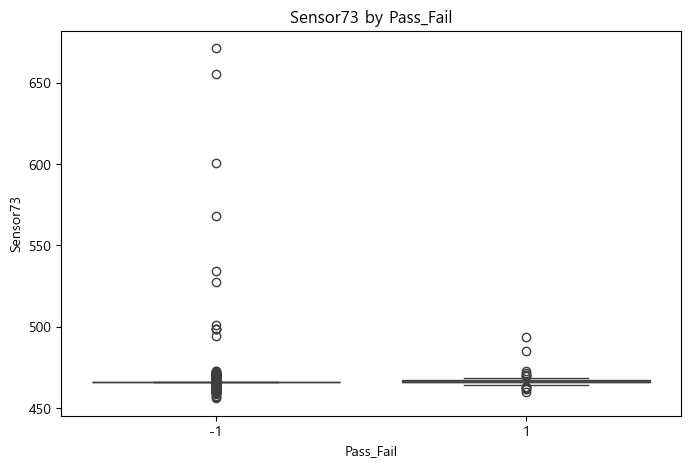

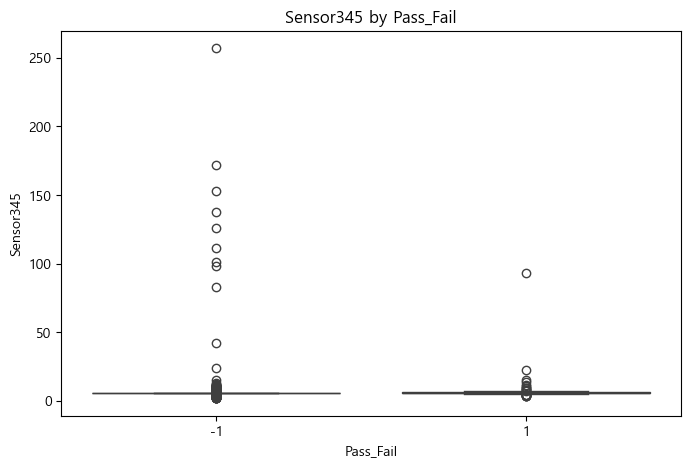

In [9]:
# 현재 X_train에 남아있는 컬럼 기준으로 feature_cols 갱신
feature_cols = X_train.columns.tolist()

outliers_result = {}

for col in feature_cols:
    Q1 = np.nanquantile(X_train[col], 0.25)
    Q3 = np.nanquantile(X_train[col], 0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower_bound) |
        (X_train[col] > upper_bound)
    ]

    outliers_result[col] = len(outliers)

outliers_result = pd.Series(outliers_result).sort_values(ascending=False)
top_features = outliers_result.head(3).index

train_df = X_train.copy()
train_df[target_col] = y_train

for col in top_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=train_df, x=target_col, y=col)
    plt.title(f"{col} by Pass_Fail")
    plt.show()

### Zero Variance

In [10]:
thresholder = VarianceThreshold(threshold=0)
_ = thresholder.fit_transform(X_train)

mask = ~thresholder.get_support()
cols_zero_var_drop = np.asarray(feature_cols)[mask].tolist()

print(f'** {len(cols_zero_var_drop)} Features to Drop by Low Variance')
print(f'{cols_zero_var_drop}')

X_train = X_train.drop(columns=cols_zero_var_drop)
X_test = X_test.drop(columns=cols_zero_var_drop)

feature_cols = X_train.columns.tolist()

** 116 Features to Drop by Low Variance
['Sensor5', 'Sensor13', 'Sensor42', 'Sensor49', 'Sensor52', 'Sensor69', 'Sensor97', 'Sensor141', 'Sensor149', 'Sensor178', 'Sensor179', 'Sensor186', 'Sensor189', 'Sensor190', 'Sensor191', 'Sensor192', 'Sensor193', 'Sensor194', 'Sensor226', 'Sensor229', 'Sensor230', 'Sensor231', 'Sensor232', 'Sensor233', 'Sensor234', 'Sensor235', 'Sensor236', 'Sensor237', 'Sensor240', 'Sensor241', 'Sensor242', 'Sensor243', 'Sensor256', 'Sensor257', 'Sensor258', 'Sensor259', 'Sensor260', 'Sensor261', 'Sensor262', 'Sensor263', 'Sensor264', 'Sensor265', 'Sensor266', 'Sensor276', 'Sensor284', 'Sensor313', 'Sensor314', 'Sensor315', 'Sensor322', 'Sensor325', 'Sensor326', 'Sensor327', 'Sensor328', 'Sensor329', 'Sensor330', 'Sensor364', 'Sensor369', 'Sensor370', 'Sensor371', 'Sensor372', 'Sensor373', 'Sensor374', 'Sensor375', 'Sensor378', 'Sensor379', 'Sensor380', 'Sensor381', 'Sensor394', 'Sensor395', 'Sensor396', 'Sensor397', 'Sensor398', 'Sensor399', 'Sensor400', 'Sens

### Remove Collinear Features

In [11]:
# Remove Collinear Features

corr_matrix = X_train[feature_cols].corr(method="pearson").abs()

threshold = 0.90
drop_cols = set()

for i in range(len(corr_matrix.columns) - 1):
    for j in range(i + 1):
        col = corr_matrix.columns[i + 1]
        row = corr_matrix.index[j]
        val = corr_matrix.iloc[j, i + 1]

        if val >= threshold:
            print(col, "|", row, "|", round(val, 2))
            drop_cols.add(col)

drop_cols = list(drop_cols)
print(len(drop_cols), "개")

X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)

feature_cols = X_train.columns.tolist()

Sensor27 | Sensor25 | 0.98
Sensor36 | Sensor34 | 1.0
Sensor50 | Sensor46 | 0.91
Sensor54 | Sensor53 | 0.94
Sensor70 | Sensor66 | 0.91
Sensor96 | Sensor94 | 0.95
Sensor101 | Sensor98 | 0.91
Sensor104 | Sensor99 | 0.99
Sensor105 | Sensor92 | 0.99
Sensor106 | Sensor93 | 0.99
Sensor123 | Sensor121 | 0.94
Sensor127 | Sensor122 | 0.96
Sensor140 | Sensor4 | 1.0
Sensor148 | Sensor16 | 0.98
Sensor148 | Sensor147 | 0.9
Sensor152 | Sensor16 | 0.98
Sensor152 | Sensor147 | 0.9
Sensor152 | Sensor148 | 0.99
Sensor154 | Sensor148 | 0.95
Sensor154 | Sensor152 | 0.91
Sensor164 | Sensor163 | 0.92
Sensor165 | Sensor164 | 0.96
Sensor174 | Sensor172 | 1.0
Sensor197 | Sensor196 | 0.91
Sensor199 | Sensor196 | 0.96
Sensor204 | Sensor67 | 0.9
Sensor205 | Sensor67 | 0.91
Sensor206 | Sensor74 | 1.0
Sensor207 | Sensor196 | 0.93
Sensor207 | Sensor199 | 0.9
Sensor207 | Sensor205 | 0.9
Sensor209 | Sensor74 | 1.0
Sensor209 | Sensor206 | 1.0
Sensor244 | Sensor109 | 0.97
Sensor245 | Sensor109 | 0.93
Sensor245 | Sensor24

### Check Variable

In [12]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("문자형 컬럼 개수:", len(cat_cols))
print(cat_cols)

문자형 컬럼 개수: 0
[]


### StandardScaler

In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### LogisticRegression

훈련 세트 점수: 0.981
테스트 세트 점수:0.880
[[339  27]
 [ 20   6]]
              precision    recall  f1-score   support

          -1       0.94      0.93      0.94       366
           1       0.18      0.23      0.20        26

    accuracy                           0.88       392
   macro avg       0.56      0.58      0.57       392
weighted avg       0.89      0.88      0.89       392



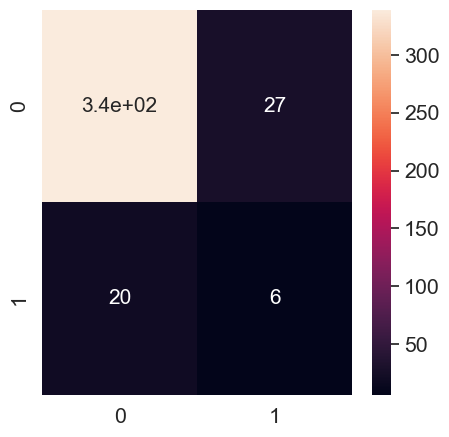

In [67]:
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train_scaled, y_train)

y_pred = model_lr.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)
plt.rcParams['figure.figsize'] = (5, 5)
sns.set_theme(style = 'dark', font_scale = 1.4)
sns.heatmap(cm, annot = True, annot_kws = {"size": 15})

print("훈련 세트 점수: {:.3f}".format(model_lr.score(X_train_scaled, y_train)))
print("테스트 세트 점수:{:.3f}".format(model_lr.score(X_test_scaled, y_test)))

print(confusion_matrix(y_test, y_pred, labels=[-1,1]))
print(classification_report(y_test, y_pred, labels=[-1,1]))

### RandomForestClassfier

훈련 세트 점수: 0.997
테스트 세트 점수:0.934
[[363   3]
 [ 23   3]]
              precision    recall  f1-score   support

          -1       0.94      0.99      0.97       366
           1       0.50      0.12      0.19        26

    accuracy                           0.93       392
   macro avg       0.72      0.55      0.58       392
weighted avg       0.91      0.93      0.91       392



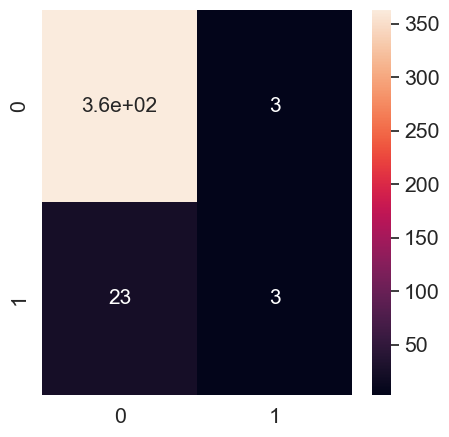

In [68]:
model_rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    max_depth=5,
    min_samples_leaf=10,
    min_samples_split=20,
    n_estimators=200
)
model_rf.fit(X_train, y_train)

y_pred = model_rf.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
plt.rcParams['figure.figsize'] = (5, 5)
sns.set_theme(style = 'dark', font_scale = 1.4)
sns.heatmap(cm, annot = True, annot_kws = {"size": 15})

print("훈련 세트 점수: {:.3f}".format(model_rf.score(X_train, y_train)))
print("테스트 세트 점수:{:.3f}".format(model_rf.score(X_test, y_test)))

print(confusion_matrix(y_test, y_pred, labels=[-1,1]))
print(classification_report(y_test, y_pred, labels=[-1,1]))

### XGBoost Algorithm

훈련 세트 점수: 1.000
테스트 세트 점수: 0.939
[[366   0]
 [ 24   2]]
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       366
           1       1.00      0.08      0.14        26

    accuracy                           0.94       392
   macro avg       0.97      0.54      0.56       392
weighted avg       0.94      0.94      0.91       392



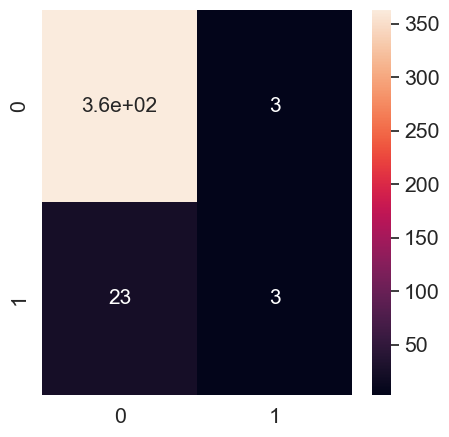

In [ ]:
y_train_xgb = y_train.replace(-1,0) 
y_test_xgb = y_test.replace(-1,0)

model_xgb = XGBClassifier(random_state=1)
model_xgb.fit(X_train, y_train_xgb)

y_pred_xgb = model_xgb.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
plt.rcParams['figure.figsize'] = (5, 5)
sns.set_theme(style = 'dark', font_scale = 1.4)
sns.heatmap(cm, annot = True, annot_kws = {"size": 15})

print("훈련 세트 점수: {:.3f}".format(model_xgb.score(X_train, y_train_xgb)))
print("테스트 세트 점수: {:.3f}".format(model_xgb.score(X_test, y_test_xgb)))

print(confusion_matrix(y_test_xgb, y_pred_xgb, labels=[0, 1]))
print(classification_report(y_test_xgb, y_pred_xgb, labels=[0, 1]))